In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wandb

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
from catboost import CatBoostClassifier
import shap

data = pd.read_csv('../data/raw/cs-training.csv', index_col=0)

TARGET_COL = 'SeriousDlqin2yrs'
X_raw = data.drop(columns=[TARGET_COL])
y = data[TARGET_COL]

print(f"Загружено признаков: {X_raw.shape[1]}, строк: {len(X_raw)}")

wandb.login()

d:\programming\python\ML\give-me-some-credit-scoring\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Загружено признаков: 10, строк: 150000


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\User\_netrc.
wandb: Currently logged in as: istaselko (istaselko-belarusian-state-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [2]:
from sklearn.base import BaseEstimator, TransformerMixin

class FeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        X_df = X.copy()
        valid_ages = X_df.loc[X_df['age'] > 0, 'age']
        self.age_median_ = float(valid_ages.median()) if len(valid_ages) > 0 else 52.0
        return self

    def transform(self, X):
        X_df = X.copy()

        X_df.loc[X_df['age'] <= 0, 'age'] = self.age_median_
        X_df['age'] = X_df['age'].clip(upper=100.0)

        due_cols = [
            'NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTime60-89DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate'
        ]
        X_df['has_past_due_anomaly'] = (X_df[due_cols] >= 96).any(axis=1).astype(int)
        for col in due_cols:
            X_df.loc[X_df[col] >= 96, col] = 0

        X_df['Total_Past_Due'] = X_df[due_cols].sum(axis=1)

        X_df['MonthlyIncome_is_missing'] = X_df['MonthlyIncome'].isna().astype(int)

        X_df['RevolvingUtilizationOfUnsecuredLines'] = X_df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=3.0)
        X_df['is_utilization_over_100'] = (X_df['RevolvingUtilizationOfUnsecuredLines'] > 1.0).astype(int)

        has_income = X_df['MonthlyIncome'].notna()
        X_df['MonthlyPayment'] = np.where(
            has_income,
            X_df['DebtRatio'].clip(upper=10.0) * X_df['MonthlyIncome'],
            X_df['DebtRatio'].clip(upper=10000.0)
        )

        deps = X_df['NumberOfDependents'].fillna(0)
        X_df['Income_Per_Person'] = X_df['MonthlyIncome'] / (deps + 1.0)

        total_lines = X_df['NumberOfOpenCreditLinesAndLoans']
        X_df['Real_Estate_Share'] = np.where(
            total_lines > 0,
            X_df['NumberRealEstateLoansOrLines'] / total_lines,
            0.0
        )
        X_df['Credit_Per_Age'] = total_lines / X_df['age']

        return X_df

fe = FeatureEngineer()
X_fe = fe.fit_transform(X_raw)

print(f"Было признаков: {X_raw.shape[1]}")
print(f"Стало признаков после Feature Engineering: {X_fe.shape[1]}")
display(X_fe.head())

Было признаков: 10
Стало признаков после Feature Engineering: 18


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,has_past_due_anomaly,Total_Past_Due,MonthlyIncome_is_missing,is_utilization_over_100,MonthlyPayment,Income_Per_Person,Real_Estate_Share,Credit_Per_Age
1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0,2,0,0,7323.197016,3040.0,0.461538,0.288889
2,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0,0,0,316.878123,1300.0,0.000000,0.100000
3,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0,2,0,0,258.914887,3042.0,0.000000,0.052632
4,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0,0,0,118.963951,3300.0,0.000000,0.166667
5,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0,1,0,0,1584.975094,63588.0,0.142857,0.142857


## Эксперимент 3: Градиентный бустинг LightGBM на расширенных признаках

Обучаем базовую конфигурацию LightGBM на матрице из 18 признаков. Используем 5-фолдовую стратифицированную кросс-валидацию, собираем OOF-вероятности и фиксируем прирост метрик относительно линейного baseline.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_lgb = np.zeros(len(X_fe))
fold_roc_aucs_lgb = []
fold_pr_aucs_lgb = []

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'n_estimators': 300,
    'learning_rate': 0.05,
    'num_leaves': 31,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X_fe, y)):
    X_train, y_train = X_fe.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X_fe.iloc[val_idx], y.iloc[val_idx]

    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(X_train, y_train)

    val_preds = model_lgb.predict_proba(X_val)[:, 1]
    oof_preds_lgb[val_idx] = val_preds

    fold_roc = roc_auc_score(y_val, val_preds)
    fold_pr = average_precision_score(y_val, val_preds)

    fold_roc_aucs_lgb.append(fold_roc)
    fold_pr_aucs_lgb.append(fold_pr)
    print(f"Fold {fold + 1} | ROC-AUC: {fold_roc:.4f} | PR-AUC: {fold_pr:.4f}")

mean_roc_auc_lgb = float(np.mean(fold_roc_aucs_lgb))
std_roc_auc_lgb = float(np.std(fold_roc_aucs_lgb))
mean_pr_auc_lgb = float(np.mean(fold_pr_aucs_lgb))
std_pr_auc_lgb = float(np.std(fold_pr_aucs_lgb))
oof_roc_auc_lgb = float(roc_auc_score(y, oof_preds_lgb))
oof_pr_auc_lgb = float(average_precision_score(y, oof_preds_lgb))

print(f"\nMean ROC-AUC (LightGBM): {mean_roc_auc_lgb:.4f} ± {std_roc_auc_lgb:.4f}")
print(f"Mean PR-AUC  (LightGBM): {mean_pr_auc_lgb:.4f} ± {std_pr_auc_lgb:.4f}")
print(f"OOF ROC-AUC  (LightGBM): {oof_roc_auc_lgb:.4f}")
print(f"OOF PR-AUC   (LightGBM): {oof_pr_auc_lgb:.4f}")

run = wandb.init(
    project="credit-scoring",
    name="03_lightgbm_fe",
    config={
        "stage": "advanced_model",
        "model_type": "LightGBM",
        "pipeline": "feature_engineering + gbdt",
        "n_estimators": 300,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "cv_type": "StratifiedKFold",
        "cv_splits": 5,
        "random_state": 42,
        "n_features": X_fe.shape[1]
    }
)

wandb.log({
    "cv_roc_auc_mean": mean_roc_auc_lgb,
    "cv_roc_auc_std": std_roc_auc_lgb,
    "cv_pr_auc_mean": mean_pr_auc_lgb,
    "cv_pr_auc_std": std_pr_auc_lgb,
    "oof_roc_auc": oof_roc_auc_lgb,
    "oof_pr_auc": oof_pr_auc_lgb
})

wandb.finish()

Fold 1 | ROC-AUC: 0.8623 | PR-AUC: 0.3952
Fold 2 | ROC-AUC: 0.8636 | PR-AUC: 0.3940
Fold 3 | ROC-AUC: 0.8696 | PR-AUC: 0.4214
Fold 4 | ROC-AUC: 0.8584 | PR-AUC: 0.3841
Fold 5 | ROC-AUC: 0.8688 | PR-AUC: 0.4060

Mean ROC-AUC (LightGBM): 0.8645 ± 0.0042
Mean PR-AUC  (LightGBM): 0.4001 ± 0.0127
OOF ROC-AUC  (LightGBM): 0.8644
OOF PR-AUC   (LightGBM): 0.3992


cv_pr_auc_mean,▁
cv_pr_auc_std,▁
cv_roc_auc_mean,▁
cv_roc_auc_std,▁
oof_pr_auc,▁
oof_roc_auc,▁
cv_pr_auc_mean,0.40011
cv_pr_auc_std,0.01269
cv_roc_auc_mean,0.86455
cv_roc_auc_std,0.00418
oof_pr_auc,0.39919


### Вывод по LightGBM

1. **Метрики качества:**
   * **Mean ROC-AUC:** 0.8645 ± 0.0042 (OOF ROC-AUC: 0.8644).
   * **Mean PR-AUC:** 0.4001 ± 0.0127 (OOF PR-AUC: 0.3992).
   * Прирост к baseline логистической регрессии с предобработкой составил **+0.0088** по ROC-AUC и **+0.0258** по PR-AUC. Целевой ориентир проекта (ROC-AUC ≥ 0.86) успешно достигнут.

2. **Причины улучшения:**
   * Деревья решений эффективно учли нелинейные зависимости и взаимодействия между новыми признаками (в частности, отношение долга к доходу и суммарные просрочки).
   * Градиентный бустинг нативно обработал пропуски в `MonthlyIncome` и `NumberOfDependents` без необходимости их принудительного заполнения медианой.

3. **Следующий шаг:**
   * Обучение альтернативного алгоритма бустинга (CatBoost) для проверки стабильности на тех же данных.

## Эксперимент 4: Градиентный бустинг CatBoost

Обучаем CatBoost на той же матрице из 18 признаков. 

В отличие от LightGBM, CatBoost строит симметричные деревья, что снижает риск переобучения и дает другую структуру разбиений в пространстве признаков. Пропуски в данных CatBoost обрабатывает нативно как отдельное направление ветвления.

In [4]:
oof_preds_cb = np.zeros(len(X_fe))
fold_roc_aucs_cb = []
fold_pr_aucs_cb = []

cb_params = {
    'iterations': 500,
    'learning_rate': 0.05,
    'depth': 6,
    'eval_metric': 'AUC',
    'loss_function': 'Logloss',
    'random_seed': 42,
    'verbose': 0
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X_fe, y)):
    X_train, y_train = X_fe.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X_fe.iloc[val_idx], y.iloc[val_idx]

    model_cb = CatBoostClassifier(**cb_params)
    model_cb.fit(X_train, y_train)

    val_preds = model_cb.predict_proba(X_val)[:, 1]
    oof_preds_cb[val_idx] = val_preds

    fold_roc = roc_auc_score(y_val, val_preds)
    fold_pr = average_precision_score(y_val, val_preds)

    fold_roc_aucs_cb.append(fold_roc)
    fold_pr_aucs_cb.append(fold_pr)
    print(f"Fold {fold + 1} | ROC-AUC: {fold_roc:.4f} | PR-AUC: {fold_pr:.4f}")

mean_roc_auc_cb = float(np.mean(fold_roc_aucs_cb))
std_roc_auc_cb = float(np.std(fold_roc_aucs_cb))
mean_pr_auc_cb = float(np.mean(fold_pr_aucs_cb))
std_pr_auc_cb = float(np.std(fold_pr_aucs_cb))
oof_roc_auc_cb = float(roc_auc_score(y, oof_preds_cb))
oof_pr_auc_cb = float(average_precision_score(y, oof_preds_cb))

print(f"\nMean ROC-AUC (CatBoost): {mean_roc_auc_cb:.4f} ± {std_roc_auc_cb:.4f}")
print(f"Mean PR-AUC  (CatBoost): {mean_pr_auc_cb:.4f} ± {std_pr_auc_cb:.4f}")
print(f"OOF ROC-AUC  (CatBoost): {oof_roc_auc_cb:.4f}")
print(f"OOF PR-AUC   (CatBoost): {oof_pr_auc_cb:.4f}")

run = wandb.init(
    project="credit-scoring",
    name="04_catboost_fe",
    config={
        "stage": "advanced_model",
        "model_type": "CatBoost",
        "pipeline": "feature_engineering + oblivious_trees",
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 6,
        "cv_type": "StratifiedKFold",
        "cv_splits": 5,
        "random_state": 42,
        "n_features": X_fe.shape[1]
    }
)

wandb.log({
    "cv_roc_auc_mean": mean_roc_auc_cb,
    "cv_roc_auc_std": std_roc_auc_cb,
    "cv_pr_auc_mean": mean_pr_auc_cb,
    "cv_pr_auc_std": std_pr_auc_cb,
    "oof_roc_auc": oof_roc_auc_cb,
    "oof_pr_auc": oof_pr_auc_cb
})

wandb.finish()

Fold 1 | ROC-AUC: 0.8656 | PR-AUC: 0.3992
Fold 2 | ROC-AUC: 0.8658 | PR-AUC: 0.3995
Fold 3 | ROC-AUC: 0.8720 | PR-AUC: 0.4217
Fold 4 | ROC-AUC: 0.8611 | PR-AUC: 0.3884
Fold 5 | ROC-AUC: 0.8698 | PR-AUC: 0.4088

Mean ROC-AUC (CatBoost): 0.8669 ± 0.0038
Mean PR-AUC  (CatBoost): 0.4035 ± 0.0112
OOF ROC-AUC  (CatBoost): 0.8668
OOF PR-AUC   (CatBoost): 0.4029


cv_pr_auc_mean,▁
cv_pr_auc_std,▁
cv_roc_auc_mean,▁
cv_roc_auc_std,▁
oof_pr_auc,▁
oof_roc_auc,▁
cv_pr_auc_mean,0.40352
cv_pr_auc_std,0.01117
cv_roc_auc_mean,0.86686
cv_roc_auc_std,0.00377
oof_pr_auc,0.40287


### Вывод по CatBoost

1. **Метрики качества:**
   * **Mean ROC-AUC:** 0.8669 ± 0.0038 (OOF ROC-AUC: 0.8668).
   * **Mean PR-AUC:** 0.4035 ± 0.0112 (OOF PR-AUC: 0.4029).
   * CatBoost превзошел LightGBM (0.8645) на **+0.0024** по ROC-AUC и показал меньший разброс между фолдами (± 0.0038 против ± 0.0042), став лучшей одиночной моделью проекта.

2. **Анализ поведения:**
   * Симметричная структура деревьев и собственная схема бинаризации вещественных признаков в CatBoost обеспечили более гладкую обобщающую способность на данных с сильным дисбалансом.

## Эксперимент 5: Ансамблирование моделей

Проверяем гипотезу о том, что объединение разнородных моделей даст прирост качества за счет компенсации индивидуальных ошибок.

Объединяем сохраненные OOF-предсказания трех архитектур:
1. Очищенная логистическая регрессия (`oof_preds_clean` из второго блокнота).
2. LightGBM (`oof_preds_lgb`).
3. CatBoost (`oof_preds_cb`).

In [5]:
baseline_oof_df = pd.read_csv('../data/processed/oof_predictions_baseline.csv')
oof_preds_lr = baseline_oof_df['pred_prob_cleaned'].values

weights = [
    (0.5, 0.5, 0.0),
    (0.6, 0.4, 0.0),
    (0.5, 0.4, 0.1),
    (0.45, 0.45, 0.1)
]

best_blend_auc = 0.0
best_blend_pr = 0.0
best_weights = None
best_blend_preds = None

print("Результаты взвешенного усреднения (CatBoost, LightGBM, LogReg):")
for w_cb, w_lgb, w_lr in weights:
    blend_preds = (w_cb * oof_preds_cb) + (w_lgb * oof_preds_lgb) + (w_lr * oof_preds_lr)
    auc = float(roc_auc_score(y, blend_preds))
    pr = float(average_precision_score(y, blend_preds))
    print(f"Веса ({w_cb:.2f}, {w_lgb:.2f}, {w_lr:.2f}) -> OOF ROC-AUC: {auc:.5f} | PR-AUC: {pr:.5f}")

    if auc > best_blend_auc:
        best_blend_auc = auc
        best_blend_pr = pr
        best_weights = (w_cb, w_lgb, w_lr)
        best_blend_preds = blend_preds

print(f"\nЛучшая комбинация весов: {best_weights}")
print(f"Итоговый OOF ROC-AUC ансамбля: {best_blend_auc:.5f} (прирост к CatBoost: {best_blend_auc - oof_roc_auc_cb:+.5f})")
print(f"Итоговый OOF PR-AUC ансамбля:  {best_blend_pr:.5f}")

run = wandb.init(
    project="credit-scoring",
    name="05_ensemble_blend",
    config={
        "stage": "ensemble",
        "model_type": "WeightedBlend",
        "weights_cb_lgb_lr": list(best_weights),
        "cv_type": "StratifiedKFold",
        "cv_splits": 5,
        "random_state": 42
    }
)

wandb.log({
    "oof_roc_auc": best_blend_auc,
    "oof_pr_auc": best_blend_pr,
    "roc_auc_gain_vs_catboost": best_blend_auc - oof_roc_auc_cb
})

wandb.finish()

Результаты взвешенного усреднения (CatBoost, LightGBM, LogReg):
Веса (0.50, 0.50, 0.00) -> OOF ROC-AUC: 0.86654 | PR-AUC: 0.40430
Веса (0.60, 0.40, 0.00) -> OOF ROC-AUC: 0.86674 | PR-AUC: 0.40449
Веса (0.50, 0.40, 0.10) -> OOF ROC-AUC: 0.86560 | PR-AUC: 0.40431
Веса (0.45, 0.45, 0.10) -> OOF ROC-AUC: 0.86556 | PR-AUC: 0.40424

Лучшая комбинация весов: (0.6, 0.4, 0.0)
Итоговый OOF ROC-AUC ансамбля: 0.86674 (прирост к CatBoost: -0.00003)
Итоговый OOF PR-AUC ансамбля:  0.40449


oof_pr_auc,▁
oof_roc_auc,▁
roc_auc_gain_vs_catboost,▁
oof_pr_auc,0.40449
oof_roc_auc,0.86674
roc_auc_gain_vs_catboost,-3e-05


### Вывод по ансамблированию

1. **Результаты взвешивания:**
   * Лучшей комбинацией стало объединение двух бустингов: **60% CatBoost + 40% LightGBM** (OOF ROC-AUC = **0.8667**, OOF PR-AUC = **0.4045**).
   * Добавление логистической регрессии (вес 0.1) ухудшает результат (ROC-AUC снижается с 0.8667 до 0.8656). Линейная модель уступает деревьям в точности разделения сложных взаимодействий и вносит шум в итоговую вероятность.

2. **Итог эксперимента:**
   * Блендинг двух бустингов дал небольшой прирост по PR-AUC (с 0.4029 до 0.4045), однако по ROC-AUC одиночный CatBoost (0.8668) работает практически идентично ансамблю.
   * Для продакшена или инференса усложнение пайплайна двумя моделями здесь избыточно: **CatBoost выбирается в качестве финальной рабочей модели**.

## 4. Интерпретация модели с помощью SHAP

Используем значения Шепли (`shap.TreeExplainer`) для финальной модели.

Строим два графика:
1. **Feature Importance (Bar Plot)** — глобальный рейтинг признаков по модулю влияния.
2. **Beeswarm Plot (Summary Plot)** — детальный график, показывающий направление влияния (повышает признак риск дефолта или снижает).

Для быстрого и стабильного расчета берем репрезентативную выборку из 3 000 клиентов.

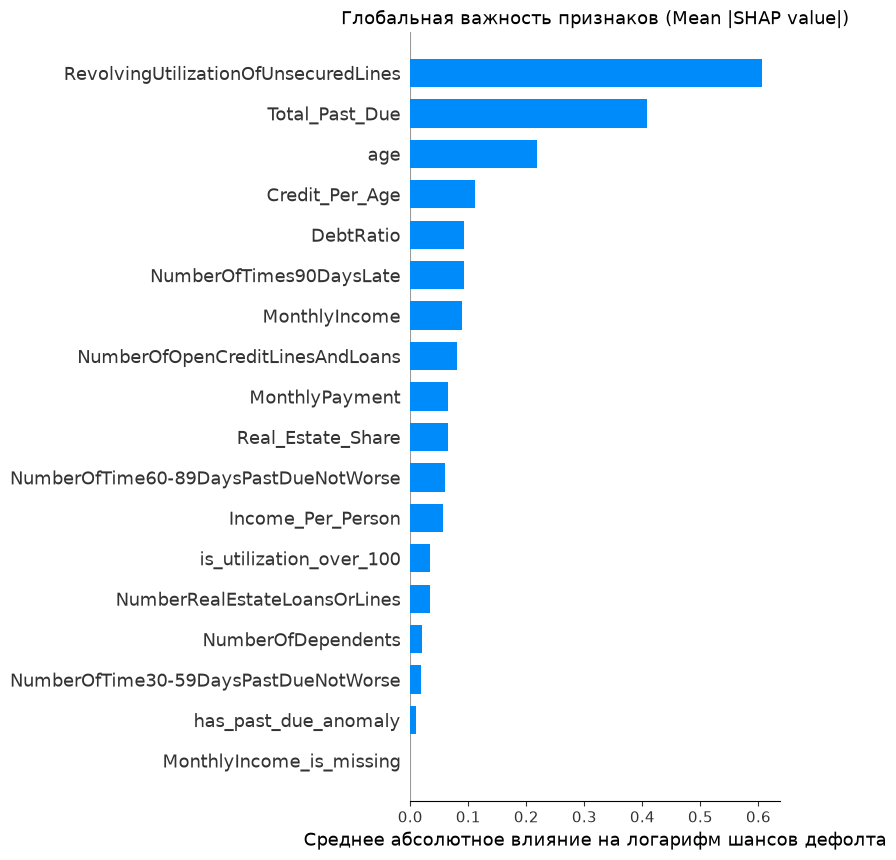

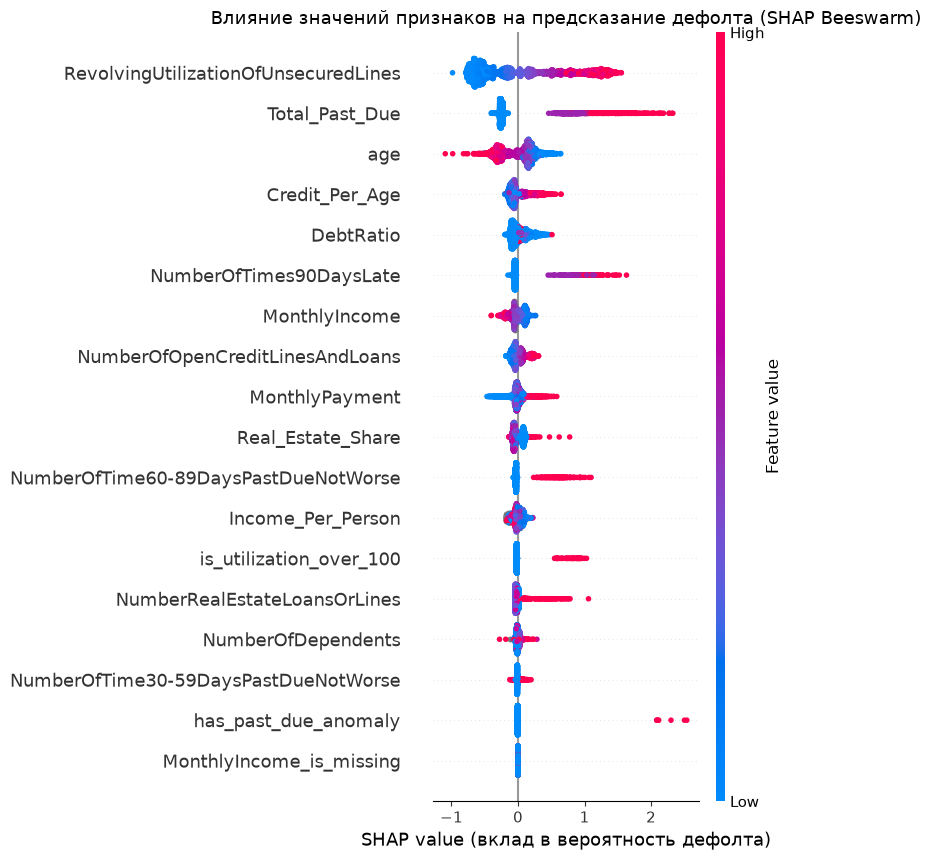

In [6]:
explainer = shap.TreeExplainer(model_cb)
sample_X = X_fe.sample(3000, random_state=42)
shap_values = explainer.shap_values(sample_X)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_X, plot_type="bar", show=False)
plt.title("Глобальная важность признаков (Mean |SHAP value|)", fontsize=13)
plt.xlabel("Среднее абсолютное влияние на логарифм шансов дефолта")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_X, show=False)
plt.title("Влияние значений признаков на предсказание дефолта (SHAP Beeswarm)", fontsize=13)
plt.xlabel("SHAP value (вклад в вероятность дефолта)")
plt.tight_layout()
plt.show()

### Вывод по интерпретации модели (SHAP Analysis)

1. **Глобальный рейтинг важности:**
   * Топ-1 признаком с большим отрывом является **`RevolvingUtilizationOfUnsecuredLines`** (среднее влияние на логарифм шансов свыше 0.60). Степень исчерпания кредитного лимита — главный определяющий фактор модели.
   * На **2-е место** в модели вышел созданный признак **`Total_Past_Due`** (суммарные просрочки, влияние ~0.41), а на **4-е место** — **`Credit_Per_Age`** (интенсивность кредитования относительно возраста). Это доказывает успешность этапа Feature Engineering: новые признаки вытеснили исходные сырые колонки по важности.
   * На **3-м месте** находится возраст (**`age`**, влияние ~0.22).

2. **Характер влияния признаков:**
   * **`RevolvingUtilizationOfUnsecuredLines`:** высокие значения (красные точки) резко сдвигают предсказание вправо (повышают риск дефолта), низкие (синие точки) — снижают риск.
   * **`Total_Past_Due` и `NumberOfTimes90DaysLate`:** даже единичные задержки платежей дают мощный положительный вклад в вероятность дефолта.
   * **`age`:** синие точки (молодые заёмщики) расположены справа от нуля (повышенный риск), а красные точки (клиенты зрелого возраста) — слева. Модель подтвердила вывод EDA о более высокой платёжной дисциплине старшего поколения.
   * **`has_past_due_anomaly`:** флаг технического сбоя БКИ при значении 1 (красные точки) дает локальный скачок риска вправо более чем на +2.0 пункта, подтверждая гипотезу о том, что спецкоды скрывали за собой проблемных заёмщиков.

## 5. Итоговое резюме экспериментов

| Эксперимент | Модель | Признаки / Предобработка | OOF ROC-AUC | OOF PR-AUC | Прирост ROC-AUC |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **01. Baseline (Naive)** | Logistic Regression | 10 сырых признаков, медиана, StandardScaler | 0.7905 | 0.3067 | — |
| **02. Baseline (Cleaned)** | Logistic Regression | Очистка по EDA (коды 96/98, клиппинг, флаги) | 0.8556 | 0.3734 | **+0.0651** |
| **03. LightGBM** | LightGBM (GBDT) | 18 признаков (Feature Engineering) | 0.8644 | 0.3992 | **+0.0739** |
| **04. CatBoost** | CatBoost (Oblivious Trees) | 18 признаков (Feature Engineering) | **0.8668** | 0.4029 | **+0.0763** |
| **05. Ensemble (Blend)** | CatBoost (60%) + LightGBM (40%) | Взвешенное среднее OOF-вероятностей | 0.8667 | **0.4045** | **+0.0762** |

### Финальный вывод:
* Очистка данных по результатам EDA дала наибольший разовый скачок метрики (+0.0651).
* Переход к градиентному бустингу и генерация доменных признаков позволили преодолеть целевой ориентир 0.86.
* В качестве финальной рабочей модели выбран **CatBoost** (ROC-AUC = 0.8668) как оптимальный по соотношению точности, стабильности и простоты поддержки без усложнения пайплайна ансамблями.
* Все 5 запусков синхронизированы в дашборде **Weights & Biases**.

## 6. Сохранение финальной модели и инференс на тестовой выборке

Обучаем финальную модель CatBoost на всей доступной обучающей выборке (150 000 строк с 18 признаками) и сохраняем веса в директорию `models/`. 

Загружаем файл `cs-test.csv`, применяем трансформер `FeatureEngineer` и формируем итоговый файл с предсказаниями вероятностей дефолта в `data/processed/test_predictions.csv`.

In [7]:
import os

os.makedirs('../models', exist_ok=True)

final_model = CatBoostClassifier(**cb_params)
final_model.fit(X_fe, y)

final_model.save_model('../models/catboost_model.cbm')
print("Финальная модель CatBoost сохранена в models/catboost_model.cbm")

test_data = pd.read_csv('../data/raw/cs-test.csv', index_col=0)
X_test_raw = test_data.drop(columns=[TARGET_COL]) if TARGET_COL in test_data.columns else test_data

X_test_fe = fe.transform(X_test_raw)
test_preds = final_model.predict_proba(X_test_fe)[:, 1]

submission = pd.DataFrame({
    'Id': test_data.index,
    'Probability': test_preds
})

submission.to_csv('../data/processed/test_predictions.csv', index=False)
print("Итоговые предсказания сохранены в data/processed/test_predictions.csv")
display(submission.head())

Финальная модель CatBoost сохранена в models/catboost_model.cbm
Итоговые предсказания сохранены в data/processed/test_predictions.csv


,Id,Probability
0,1,0.056858
1,2,0.044430
2,3,0.014506
3,4,0.080227
4,5,0.113836
